In [1]:
import numpy as np
import pandas as pd

In [2]:

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
 #task1
 #1
print(df.shape)
print(df.shape[0])
print(df.shape[1])
#2
print(list(df.columns))
#33. Display the data type of each variable.
print(df.dtypes)
print("-----------")
#4. Identify any missing values.
print(df.isna().sum())


#Briefly describe the dataset in 3–5 sentences.
#تحتوي مجموعه من البيانات على معلومات عن 891 راكبا #
#مثل العمر والجنس بالاضافه الى معلومات السفر مثل فئة التذكره والاجره
#يشيرمتغير النجاه الى ما اذا كان الركبا قد نجا 1 وان م ينجو 0



(891, 12)
891
12
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object
-----------
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
#name|categrical|nominal
#sex|categrical|nominal
#age|numrical|continuse
#sibsp|numrical|discrete
#parch|numrical|discrete
#ticket|nominal|catagrical
#cabin|categrical|nominal
#Embarked|categorical|nominal

In [ ]:
# Task 3 - Question 1: What is the target variable?
target = "Survived"
y = df[target]

print("Target variable:", target)
print(y.value_counts())

Target variable: Survived
Survived
0    549
1    342
Name: count, dtype: int64


In [ ]:
# Task 3 - Question 2: Which variables are considered input features?
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = df[features]

print("Input features:", features)
X.head()

Input features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


Survived is called the dependent variable because it is the outcome we want to predict based on the input features. Its predicted value depends on the information provided by those features.

The remaining variables are called independent variables because they are used as input features to explain or predict the target variable. They provide information that may help the model identify patterns associated with survival.

In [3]:
# Random Sample (30%)
random_sample = df.sample(frac=0.30, random_state=42)

# Stratified Sample (30%) based on Survived
stratified_sample = df.groupby("Survived").sample(
    frac=0.30, random_state=42
)

# Compare sizes
print("Population size:", len(df))
print("Random sample size:", len(random_sample))
print("Stratified sample size:", len(stratified_sample))

# Compare class distributions
comparison = pd.DataFrame({
    "Population (%)": df["Survived"].value_counts(normalize=True) * 100,
    "Random (%)": random_sample["Survived"].value_counts(normalize=True) * 100,
    "Stratified (%)": stratified_sample["Survived"].value_counts(normalize=True) * 100
})

print(comparison.round(2))

Population size: 891
Random sample size: 267
Stratified sample size: 268
          Population (%)  Random (%)  Stratified (%)
Survived                                            
0                  61.62        58.8           61.57
1                  38.38        41.2           38.43


In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. **What is the population?**  
The population is the entire Titanic dataset, containing 891 passengers.

2. **What is the sample?**  
A sample is a subset of the population. We created two samples: a random sample of 30% of the dataset and a stratified sample of 30% based on the Survived variable.

3. **Compare the sizes of the population and the two samples.**  
The population contains 891 passengers. The random sample contains 267 passengers, and the stratified sample also contains 267 passengers. Each sample represents approximately 30% of the population.

4. **Which sampling method better preserves the original class distribution?**  
Stratified sampling better preserves the original class distribution because it selects 30% from each Survived class. This keeps the proportions of survivors and non-survivors close to those in the population.

5. **Explain why representative sampling is important in Machine Learning.**  
Representative sampling helps ensure that the sample reflects the population. It reduces sampling bias, helps the model learn relevant patterns, and provides a more reliable evaluation of its performance on new data.

In [6]:
df = pd.read_csv(url)
numerical_data = df.select_dtypes('number')[['Age','SibSp','Fare']]

print("mean","="*50)
print(numerical_data.mean())
print("median","="*50)
print(numerical_data.median())
print("mode","="*50)
print(numerical_data.mode())
print("min","="*50)
print(numerical_data.min())
print("max","="*50)
print(numerical_data.max())
print("range","="*50)
print(numerical_data.max() - numerical_data.min()) # range
print("variance","="*50)
print(numerical_data.var())
print("standard diviation","="*50)
print(numerical_data.std())


# 1. Which variable has the highest average?                 Age
# 2. Which variable has the greatest variability?            Fare
# 3. Are the mean and median close?                          yes close, but not close for 'Fare'
# 4. What does this indicate about the data distribution?    there are outliers in Fare

mean ==================================================
Age      29.699118
SibSp     0.523008
Fare     32.204208
dtype: float64
median ==================================================
Age      28.0000
SibSp     0.0000
Fare     14.4542
dtype: float64
mode ==================================================
    Age  SibSp  Fare
0  24.0      0  8.05
min ==================================================
Age      0.42
SibSp    0.00
Fare     0.00
dtype: float64
max ==================================================
Age       80.0000
SibSp      8.0000
Fare     512.3292
dtype: float64
range ==================================================
Age       79.5800
SibSp      8.0000
Fare     512.3292
dtype: float64
variance ==================================================
Age       211.019125
SibSp       1.216043
Fare     2469.436846
dtype: float64
standard diviation ==================================================
Age      14.526497
SibSp     1.102743
Fare     49.693429
dtype: float64


<Axes: >

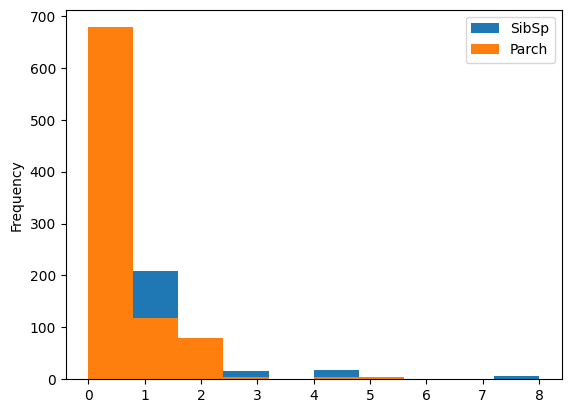

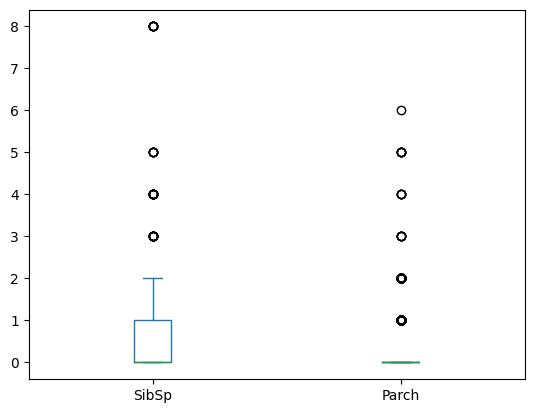

In [5]:
#task 6
two_num_variables = df[['SibSp','Parch']]
two_num_variables.plot.hist()
two_num_variables.plot.box()

# 1. Is the distribution approximately symmetric or skewed?          skewed right
# 2. Are there any outliers?                                         Yes, there are outliers.
# 3. Which statistic is more affected by outliers: Mean or Median?   Mean
# 4. Explain your answer using the plots.                            we can see the points out of the box these are the outliers.

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

            Age     SibSp     Parch      Fare
Age    1.000000 -0.308247 -0.189119  0.096067
SibSp -0.308247  1.000000  0.414838  0.159651
Parch -0.189119  0.414838  1.000000  0.216225
Fare   0.096067  0.159651  0.216225  1.000000
              Age     SibSp     Parch         Fare
Age    211.019125 -4.163334 -2.344191    73.849030
SibSp   -4.163334  1.216043  0.368739     8.748734
Parch   -2.344191  0.368739  0.649728     8.661052
Fare    73.849030  8.748734  8.661052  2469.436846


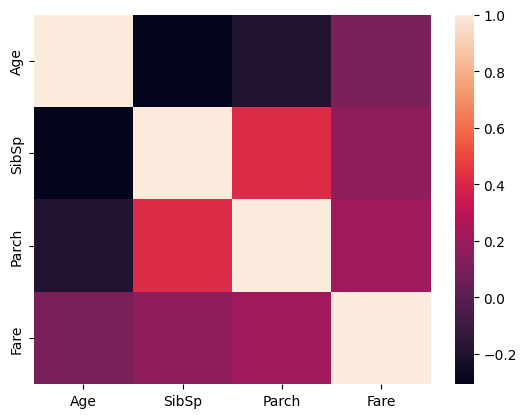

In [9]:
#task 7

numerical_data2 = df[['Age','SibSp','Parch','Fare']]
# 1. Compute the Correlation Matrix.
Correlation_Matrix = numerical_data2.corr()
print(Correlation_Matrix)
# 2. Visualize it using a Heatmap.
sns.heatmap(Correlation_Matrix)
# 3. Compute the Covariance Matrix.
Covariance_Matrix = numerical_data2.cov()
print(Covariance_Matrix)
# Then answer:
# 1. Which variables have the strongest positive correlation?      Parch & SibSp
# 2. Which variables have little or no relationship?               Age & SibSp
# 3. What is the difference between Correlation and Covariance?    Correlation direction and the strength |  Covariance direction of a relationship
# 4. Which one is easier to interpret? Why?

              Age       SibSp       Parch        Fare
count  714.000000  891.000000  891.000000  891.000000
mean    29.699118    0.523008    0.381594   32.204208
std     14.526497    1.102743    0.806057   49.693429
min      0.420000    0.000000    0.000000    0.000000
25%     20.125000    0.000000    0.000000    7.910400
50%     28.000000    0.000000    0.000000   14.454200
75%     38.000000    1.000000    0.000000   31.000000
max     80.000000    8.000000    6.000000  512.329200
Axes(0.125,0.11;0.775x0.77)


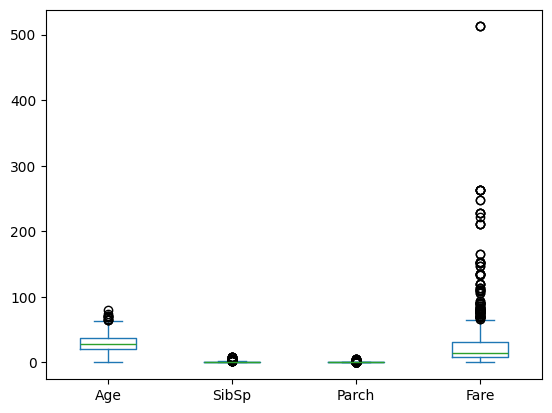

In [10]:
#task8
print(df[['Age','SibSp','Parch','Fare']].describe())
print(df[['Age','SibSp','Parch','Fare']].plot.box())
# Which variable has the largest spread?        Fare 49.693429
# Which variable contains outliers?             Fare
# Which variables appear to be related?         Parch & SibSp
# Which variable has the highest average?       Fare
# Which variable may require preprocessing?     age (has 177 null values) & Fare ( right skewed )

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

In [12]:
# task 9
# Imagine you are preparing this dataset for a Machine Learning model.
# Answer the following:
# 1. Which feature do you think will be most useful for predicting survival?     sex
# 2. Which feature would you consider removing? Why?                             Passenger ID and name: they are useless.
# 3. Based on the Correlation and Covariance analysis, which variables do you
# expect to contribute the most if PCA were applied?                             Fare
# 4. What preprocessing steps would you perform before training the model?       drop the useless columns, and fill the NA, and make labelencoder for categorical features
# Support your answers using evidence from your statistical analysis.

drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived']
X = df.drop(columns=drop_cols)
y = df['Survived']

# Handle missing values (simple imputation)
X['Age'] = X['Age'].fillna(X['Age'].median())
X['Fare'] = X['Fare'].fillna(X['Fare'].median())
X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

# Encode categorical variables ('Sex' and 'Embarked')
X['Sex'] = LabelEncoder().fit_transform(X['Sex'])
X['Embarked'] = LabelEncoder().fit_transform(X['Embarked'])

# 3. Train a Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X, y)

# 4. Get feature importances
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance_df)

    Feature  Importance
5      Fare    0.274307
1       Sex    0.262157
2       Age    0.257884
0    Pclass    0.088450
3     SibSp    0.045523
4     Parch    0.038107
6  Embarked    0.033572
